## Planning:
- Load data
- Maximum Parameter with Optuna
- Blending with Optuna
- Output

In [2]:
import numpy as np
import pandas as pd
import optuna
from sklearn.metrics import roc_auc_score

# import OS
import os

In [3]:
train = pd.read_csv("data/train.csv")
train_data = train[["id","is_fraud"]]

test = pd.read_csv("data/test.csv")
test_data = test[["id"]]

submit = pd.read_csv("data/sample_submission.csv")

In [4]:
folder_oof = "./oof"
folder_sub = "./sub"

In [5]:
content_oof = os.listdir(folder_oof)
content_sub = os.listdir(folder_sub)

In [6]:
for oof in content_oof:
    path_oof = folder_oof+"/"+oof
    oof_data = pd.read_csv(path_oof)
    train_data = pd.concat([train_data,oof_data.iloc[:,[1]]],axis=1)

In [7]:
for sub in content_sub:
    path_sub = folder_sub+"/"+sub
    sub_data = pd.read_csv(path_sub)
    test_data = pd.concat([test_data,sub_data.iloc[:,[1]]],axis=1)

## Data Process for Modeling

In [75]:
X = train_data.drop(columns=["id","is_fraud"])
y = train_data["is_fraud"]
X_test = test_data.drop(columns=["id"])
X_test.columns = X.columns

In [57]:
X = X.drop(columns=["log_5cv"])
X_test = X_test.drop(columns=["log_5cv"])

In [60]:
oof_matrix = X.values 
y_true_array = y.values
num_models = oof_matrix.shape[1]

In [61]:
def objective(trial):
    weights = []
    remaining_weight = 1.0
    
    for i in range(num_models - 1):
        # ensure upper bound is never less than 0.0
        high = max(0.0,min(1.0,remaining_weight))
        w = trial.suggest_float(f'w_{i}', 0.0, high)
        weights.append(w)
        remaining_weight -= w
    weights.append(max(0.0, min(1.0, remaining_weight)))
    
    weights = np.array(weights, dtype=np.float64)
    
    # Fast dot product on matrix
    blended_preds = np.dot(oof_matrix, weights)
    return roc_auc_score(y_true_array, blended_preds)

In [62]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=300)

C:\Users\User\miniconda3\envs\ml-blueprint\Lib\site-packages\optuna\samplers\_tpe\sampler.py:526: RuntimeWarning: invalid value encountered in subtract
  acq_func_vals = log_likelihoods_below - log_likelihoods_above
C:\Users\User\miniconda3\envs\ml-blueprint\Lib\site-packages\optuna\samplers\_tpe\sampler.py:526: RuntimeWarning: invalid value encountered in subtract
  acq_func_vals = log_likelihoods_below - log_likelihoods_above
C:\Users\User\miniconda3\envs\ml-blueprint\Lib\site-packages\optuna\samplers\_tpe\sampler.py:526: RuntimeWarning: invalid value encountered in subtract
  acq_func_vals = log_likelihoods_below - log_likelihoods_above
C:\Users\User\miniconda3\envs\ml-blueprint\Lib\site-packages\optuna\samplers\_tpe\sampler.py:526: RuntimeWarning: invalid value encountered in subtract
  acq_func_vals = log_likelihoods_below - log_likelihoods_above
C:\Users\User\miniconda3\envs\ml-blueprint\Lib\site-packages\optuna\samplers\_tpe\sampler.py:526: RuntimeWarning: invalid value encounte

In [63]:
# Reconstruct the optimal weights array
best_params = study.best_params
final_weights = []
rem = 1.0
for i in range(num_models - 1):
    w = best_params[f'w_{i}']
    final_weights.append(w)
    rem -= w
final_weights.append(rem)
final_weights = np.array(final_weights, dtype=np.float64)

print(f"🥇 Best OOF AUC Score: {study.best_value:.6f}")

🥇 Best OOF AUC Score: 0.947149


In [64]:
final_weights

array([0.02513207, 0.0020922 , 0.07526872, 0.33463291, 0.21700368,
       0.0145255 , 0.10536397, 0.03705993, 0.02664652, 0.02387045,
       0.02105168, 0.02136036, 0.01550031, 0.01187116, 0.00695022,
       0.0076834 , 0.00757164, 0.00769768, 0.03871762])

In [65]:
# -------------------------------------------------------------------------
# 4. PREDICT ON UNSEEN TEST DATAFRAME
# -------------------------------------------------------------------------
# Ensure your test columns are in the exact same order as your OOF columns!
# assert list(X.columns) == list(X_test.columns), "Columns must match exactly!"

In [66]:
# Compute the final blended predictions
final_blend = np.dot(X_test.values, final_weights)

In [67]:
submit["is_fraud"] = final_blend

In [68]:
submit.to_csv("Blending Optuna v2.csv",index=False)

In [76]:
# check the correlation between variable
fin_corr = X.corr()

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

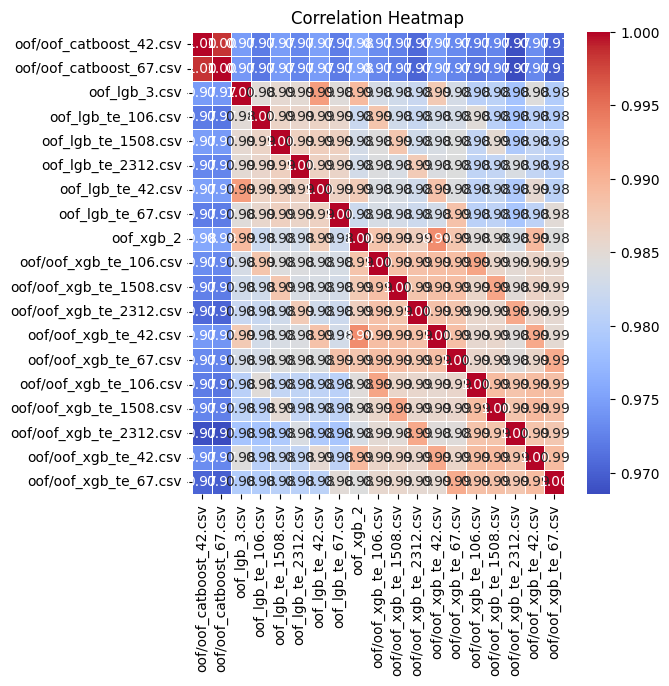

In [73]:
plt.figure(figsize=(6,6))
sns.heatmap(fin_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [77]:
fin_corr

,oof/oof_catboost_42.csv,oof/oof_catboost_67.csv,oof_lgb_3.csv,oof_lgb_te_106.csv,oof_lgb_te_1508.csv,oof_lgb_te_2312.csv,oof_lgb_te_42.csv,oof_lgb_te_67.csv,log_5cv,oof_xgb_2,oof/oof_xgb_te_106.csv,oof/oof_xgb_te_1508.csv,oof/oof_xgb_te_2312.csv,oof/oof_xgb_te_42.csv,oof/oof_xgb_te_67.csv,oof/oof_xgb_te_106.csv,oof/oof_xgb_te_1508.csv,oof/oof_xgb_te_2312.csv,oof/oof_xgb_te_42.csv,oof/oof_xgb_te_67.csv
oof/oof_catboost_42.csv,1.000000,0.998407,0.974602,0.972086,0.974747,0.972934,0.974947,0.972222,0.974844,0.975705,0.973356,0.972374,0.970679,0.974347,0.973184,0.972002,0.972796,0.968923,0.973436,0.970313
oof/oof_catboost_67.csv,0.998407,1.000000,0.974241,0.971725,0.974489,0.972740,0.974633,0.972041,0.974635,0.975254,0.972904,0.972012,0.970359,0.973982,0.972828,0.971590,0.972453,0.968558,0.972905,0.969852
oof_lgb_3.csv,0.974602,0.974241,1.000000,0.984819,0.985263,0.985054,0.991796,0.984538,0.954500,0.989209,0.983365,0.982802,0.982022,0.987561,0.983213,0.980505,0.980770,0.978701,0.984397,0.979899
oof_lgb_te_106.csv,0.972086,0.971725,0.984819,1.000000,0.986221,0.985825,0.986351,0.985659,0.952672,0.982151,0.988119,0.982729,0.981863,0.983033,0.983234,0.984656,0.980503,0.978644,0.980432,0.979865
oof_lgb_te_1508.csv,0.974747,0.974489,0.985263,0.986221,1.000000,0.986707,0.986970,0.986685,0.955185,0.983168,0.984293,0.988047,0.982717,0.983639,0.984223,0.981400,0.985236,0.979534,0.981566,0.980658
oof_lgb_te_2312.csv,0.972934,0.972740,0.985054,0.985825,0.986707,1.000000,0.986599,0.986075,0.953979,0.982967,0.984107,0.983583,0.987468,0.983993,0.984198,0.981119,0.981338,0.983684,0.981415,0.980675
oof_lgb_te_42.csv,0.974947,0.974633,0.991796,0.986351,0.986970,0.986599,1.000000,0.986524,0.954059,0.987247,0.983842,0.983586,0.982786,0.988431,0.984072,0.980997,0.981598,0.979493,0.985375,0.980757
oof_lgb_te_67.csv,0.972222,0.972041,0.984538,0.985659,0.986685,0.986075,0.986524,1.000000,0.952906,0.982320,0.983479,0.983144,0.982400,0.982975,0.988418,0.980665,0.980946,0.978990,0.980874,0.984821
log_5cv,0.974844,0.974635,0.954500,0.952672,0.955185,0.953979,0.954059,0.952906,1.000000,0.958703,0.957314,0.956067,0.954596,0.956656,0.956848,0.957079,0.957669,0.954192,0.957027,0.955526
oof_xgb_2,0.975705,0.975254,0.989209,0.982151,0.983168,0.982967,0.987247,0.982320,0.958703,1.000000,0.988215,0.987500,0.986834,0.993064,0.988008,0.984642,0.984667,0.983445,0.989349,0.984279
